# 06 — Wave probability (`EXP-H04`)

## 1. Objective
Test whether probability-aware Wave decisions improve after-cost risk-adjusted outcomes under a frozen volatility-targeted sizer.

## 2. Hypothesis
First-passage probability decisions improve after-cost Sharpe versus hard-label Wave and always-in-market at 5, 15, and 60 minutes. Terminal-return probability is a registered secondary endpoint.

## 3. Null
Probability-aware Wave adds no after-cost Sharpe improvement over both controls at every declared horizon.

## 4. Information set
BTCUSDT one-minute OHLC known at each decision close. H1 supplies the declared unconditional return family. H2, H3, and H20 are excluded unless sealed-retained.

## 5. Dataset
`btcusdt-1m`, bound to its frozen manifest.

## 6. Data quality
The standard minute-bar audit applies. Missing path minutes, unavailable trailing volatility, endpoint truncation, and same-bar target/stop ties are counted.

## 7. Labels
The primary label is target-before-stop under symmetric one-sigma trailing-volatility barriers. When target and stop trade in the same minute, the stop wins. The secondary label is terminal return sign.

## 8. Baseline
Hard-label Wave always selects its preferred direction. Always-in-market is continuously long. Every rule uses the same frozen volatility target, gross cap, and cost model.

## 9. Model family
Training-window first-passage event frequencies use fixed Laplace smoothing. The terminal forecast uses the H1-selected Gaussian or Student-t density. Probability-aware rules may emit NO-TRADE when expected edge does not clear round-trip cost.

## 10. Splits
24-month train, 6-month validation, 6-month step, and final 12-month untouched test.

## 11. Configuration
The source of truth is `research.protocol.H4_CONFIG`. Development cannot retain H4. Sealed confirmation requires sealed H1, committed code, the registered digest, and immutable object versions.

In [1]:
import os
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
while root != root.parent and not (root / "research" / "__init__.py").exists():
    root = root.parent
if not (root / "research" / "__init__.py").exists():
    raise RuntimeError("open this notebook from the trading repository")
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.environ.setdefault("AWS_PROFILE", "trading")
os.environ.setdefault("AWS_DEFAULT_REGION", "ap-southeast-2")
os.environ.setdefault("DATA_STORE", "s3")
os.environ.setdefault("S3_BUCKET", "trading-data-centheos")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.6g}".format)

from research.registry import config_digest, load_record
from research.report import (
    confirmation_blockers,
    economic_summary,
    probability_summary,
    quality_table,
    record_development_decision,
)

## 5–6. Dataset and data quality

Reload and verify the frozen single-series manifest. Collector rows appended after the freeze are counted and excluded.

In [2]:
from research.evaluate import align_to_frozen_dataset
from research.load import load_research_bars
from research.manifest import load_manifest
from research.protocol import H4_CONFIG

MANIFEST_PATH = root / "research" / "registry" / "datasets" / "btcusdt-1m.json"
manifest = load_manifest(MANIFEST_PATH)
loaded_bars, objects = load_research_bars(
    venue=H4_CONFIG["venue"],
    symbol=H4_CONFIG["symbol"],
    timeframe=H4_CONFIG["timeframe"],
    bucket=H4_CONFIG["bucket"],
    profile=H4_CONFIG["profile"],
    region=H4_CONFIG["region"],
)
bars, quality, collector_rows_after_freeze = align_to_frozen_dataset(
    loaded_bars, manifest, objects
)
print("dataset_id:", manifest.dataset_id)
print("dataset_digest:", manifest.digest)
print("frozen_window:", manifest.start, "to", manifest.end)
print("collector_rows_after_freeze:", collector_rows_after_freeze)
display(quality_table({H4_CONFIG["symbol"]: quality}))

Excluded 317 collector rows after frozen end 2026-10-26T06:22:00+00:00; ohlcv/binance/BTCUSDT/1m/2026.parquet etag b0d44f18eb613200b2a60b3c53423626 -> 2c8a429afb738abc814b6e900596811e, size 5811263 -> 5819792


dataset_id: btcusdt-1m
dataset_digest: d67871b2eebd796cb37c7cafa89677fbca4b31ad0bdae959a5f0e2efeecc6c88
frozen_window: 2020-01-01T00:00:00+00:00 to 2026-10-26T06:22:00+00:00
collector_rows_after_freeze: 317


,rows_in,rows_kept,duplicate_timestamps,off_grid_timestamps,nonpositive_prices,inconsistent_ohlc,missing_minutes,largest_gap_minutes
series,,,,,,,,
BTCUSDT,3585983,3585983,0,0,0,0,0,1


## 12–17. Evaluation

12. Statistical evaluation: Brier score and log loss for first-passage and terminal probabilities.
13. Economic evaluation: after-cost Sharpe under one frozen volatility-targeted sizer.
14. Calibration: predicted event rates versus realised event rates by origin.
15. Ablation: probability-aware first passage, terminal probability, hard-label Wave, and always-in-market.
16. Robustness: every registered rolling origin and all declared horizons must be complete.
17. Failure analysis: failed origins and every label exclusion remain visible; they are never scored as zero advantage.

In [3]:
from research.evaluate import evaluate_h4, h4_development_decision, h4_economic_comparison

CONFIG = H4_CONFIG
EXPERIMENT_ID = CONFIG["experiment_id"]
RECORD_PATH = root / "research" / "registry" / "EXP-H04.json"
H1_RECORD_PATH = root / "research" / "registry" / "EXP-H01.json"
record = load_record(RECORD_PATH)
h1_record = load_record(H1_RECORD_PATH)
evaluation = evaluate_h4(bars, h1_record, CONFIG)
if evaluation.sealed_access:
    raise RuntimeError("development notebook read the sealed test")
comparison = h4_economic_comparison(evaluation.economic_scores)
verdict = h4_development_decision(comparison).iloc[0]
economics = economic_summary(evaluation.economic_scores)
calibration = probability_summary(evaluation.probability_scores)
GATE_H1_RECORD = h1_record
GATE_OBJECTS = manifest.objects
print("config_digest:", config_digest(CONFIG))
print("H1_family:", evaluation.h1_family)
print("sealed_boundary:", evaluation.boundary)
print("development_null_decision:", verdict.null_decision)
print("working_rule:", verdict.benchmark)

H4 5m barrier labels exclusions: gaps=0 volatility=60 endpoints=5 stop_first_ties=3381
H4 15m barrier labels exclusions: gaps=0 volatility=60 endpoints=15 stop_first_ties=892
H4 60m barrier labels exclusions: gaps=0 volatility=60 endpoints=60 stop_first_ties=504
Excluded 1 close rows from one-minute baseline returns
H4 development has 1 unavailable one-minute economic returns
Excluded 1 close rows from one-minute baseline returns


config_digest: ba39c8e6d2070dd3cc66551399b21ddd5aca79e26348cb6f685d4232bee12562
H1_family: student_t
sealed_boundary: 2025-10-26 00:00:00+00:00
development_null_decision: reject
working_rule: first_passage_probability


## How to read the scores

Sharpe and returns are net of the same turnover cost for every rule. The primary H4 gate requires first-passage probability to beat both controls in mean and median Sharpe at every horizon. Brier score and log loss are calibration diagnostics, not trading returns.

In [4]:
display(comparison)
display(economics)
display(calibration)
display(evaluation.diagnostics)
if evaluation.failures:
    display(pd.DataFrame(evaluation.failures))

,horizon_minutes,mean_sharpe,median_sharpe,mean_vs_hard_label,median_vs_hard_label,mean_vs_always,median_vs_always,origins,expected_origins
0,5,0,0,2.54393,2.81466,0.9266,0.487556,7,7
1,15,0,0,2.53362,2.81369,0.936686,0.495832,7,7
2,60,-0.45917,0,2.06857,2.45482,0.483202,0.299171,7,7


,horizon_minutes,model,average_absolute_position,average_turnover,max_drawdown,no_trade_rate,sharpe,total_simple_return
0,5,always_in_market,0.911011,0.00289246,-0.344082,0,-0.487556,-0.1352
1,5,first_passage_probability,0,0,0,1,0,0
2,5,hard_label_wave,0.911011,0.00289246,-0.504092,0,-2.81466,-0.39091
3,5,terminal_return_probability,0,0,0,1,0,0
4,15,always_in_market,0.911008,0.00289257,-0.344082,0,-0.495832,-0.136691
5,15,first_passage_probability,0,0,0,1,0,0
6,15,hard_label_wave,0.911008,0.00289257,-0.504092,0,-2.81369,-0.390805
7,15,terminal_return_probability,0,0,0,1,0,0
8,60,always_in_market,0.910992,0.0028916,-0.344082,0,-0.499467,-0.13733
9,60,first_passage_probability,0,0,0,1,0,0


,horizon_minutes,model,event,probability,event_rate,brier_score,log_loss
0,5,first_passage_probability,long_target_before_stop,0.251259,0.251443,0.188257,0.564017
1,5,first_passage_probability,short_target_before_stop,0.254727,0.255188,0.190095,0.568038
2,5,terminal_return_probability,positive_terminal_return,0.500766,0.500217,0.250001,0.693149
3,15,first_passage_probability,long_target_before_stop,0.258503,0.264349,0.194522,0.577696
4,15,first_passage_probability,short_target_before_stop,0.267134,0.268098,0.196236,0.581396
5,15,terminal_return_probability,positive_terminal_return,0.50134,0.501383,0.250002,0.693151
6,60,first_passage_probability,long_target_before_stop,0.2699,0.2728,0.198384,0.586033
7,60,first_passage_probability,short_target_before_stop,0.284062,0.277642,0.200654,0.590972
8,60,terminal_return_probability,positive_terminal_return,0.502668,0.507418,0.250006,0.693159


,horizon_minutes,barrier_labels,barrier_gap_exclusions,barrier_volatility_exclusions,barrier_endpoint_exclusions,intrabar_stop_first_ties,terminal_gap_exclusions,terminal_nonpositive_exclusions,terminal_endpoint_exclusions
0,5,3585918,0,60,5,3381,0,0,5
1,15,3585908,0,60,15,892,0,0,15
2,60,3585863,0,60,60,504,0,0,60


## Development economic plots

These plots show median after-cost Sharpe and NO-TRADE frequency. They use development origins only.

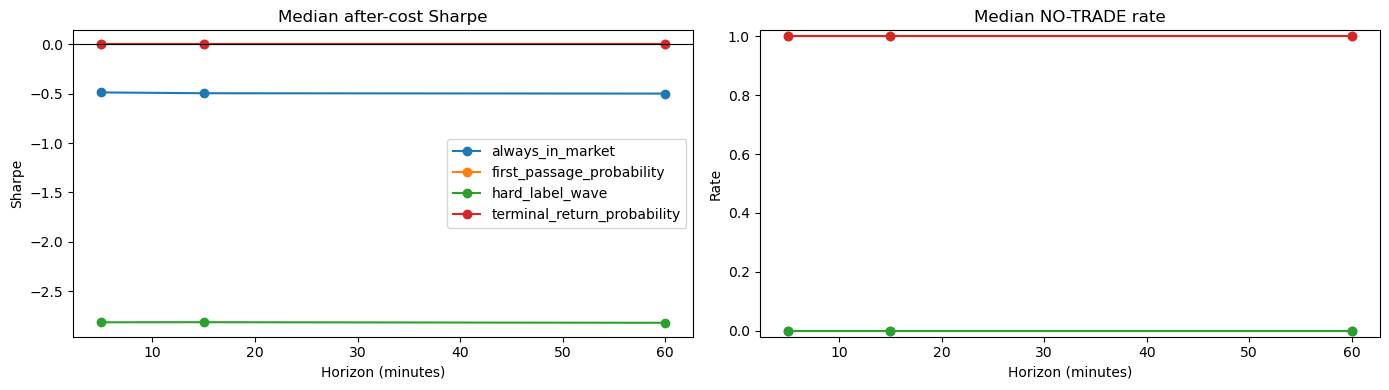

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(14, 4))
for model, rows in economics.groupby("model"):
    ordered = rows.sort_values("horizon_minutes")
    axes[0].plot(ordered["horizon_minutes"], ordered["sharpe"], marker="o", label=model)
    axes[1].plot(ordered["horizon_minutes"], ordered["no_trade_rate"], marker="o", label=model)
axes[0].axhline(0.0, color="black", linewidth=0.8)
axes[0].set(title="Median after-cost Sharpe", xlabel="Horizon (minutes)", ylabel="Sharpe")
axes[1].set(title="Median NO-TRADE rate", xlabel="Horizon (minutes)", ylabel="Rate", ylim=(-0.02, 1.02))
axes[0].legend()
figure.tight_layout()
plt.show()

## Probability calibration

A calibrated event probability should lie near the diagonal when predicted and realised rates are compared. Lower Brier score is better.

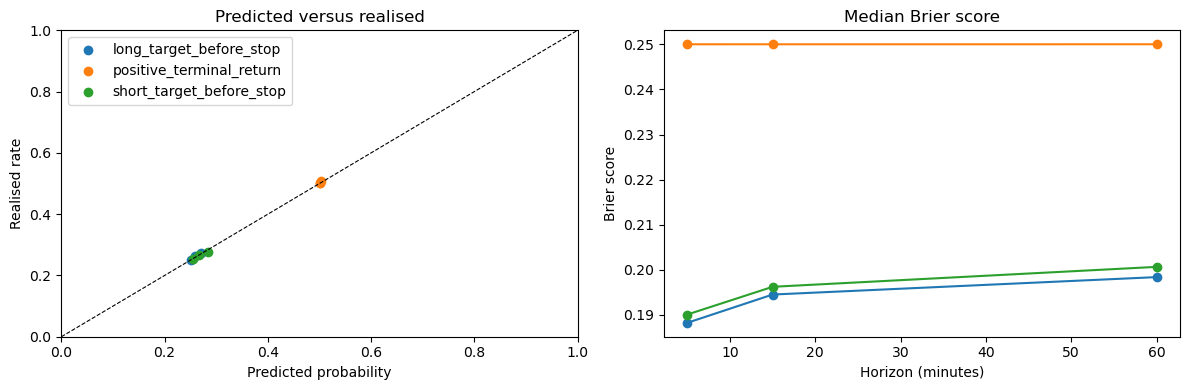

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for event, rows in calibration.groupby("event"):
    axes[0].scatter(rows["probability"], rows["event_rate"], label=event)
    axes[1].plot(rows["horizon_minutes"], rows["brier_score"], marker="o", label=event)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="black", linewidth=0.8)
axes[0].set(title="Predicted versus realised", xlabel="Predicted probability", ylabel="Realised rate", xlim=(0, 1), ylim=(0, 1))
axes[1].set(title="Median Brier score", xlabel="Horizon (minutes)", ylabel="Brier score")
axes[0].legend()
figure.tight_layout()
plt.show()

## Fitted probability state

The table retains each origin's frozen probability and realised event rate. It makes constant-within-origin H1 and categorical forecasts explicit rather than implying minute-level refits.

In [7]:
probability_state = evaluation.probability_scores[
    ["origin", "horizon_minutes", "model", "event", "observations", "probability", "event_rate", "brier_score", "log_loss"]
].sort_values(["origin", "horizon_minutes", "model", "event"])
display(probability_state)

,origin,horizon_minutes,model,event,observations,probability,event_rate,brier_score,log_loss
0,20220101,5,first_passage_probability,long_target_before_stop,260635,0.254482,0.261089,0.192965,0.574308
1,20220101,5,first_passage_probability,short_target_before_stop,260635,0.262751,0.263464,0.194051,0.576651
2,20220101,5,terminal_return_probability,positive_terminal_return,260635,0.501734,0.497339,0.250012,0.693172
21,20220101,15,first_passage_probability,long_target_before_stop,260625,0.258503,0.268535,0.196525,0.582057
22,20220101,15,first_passage_probability,short_target_before_stop,260625,0.27229,0.274003,0.198928,0.587207
...,...,...,...,...,...,...,...,...,...
40,20250101,15,first_passage_probability,short_target_before_stop,260625,0.264461,0.269606,0.196945,0.582934
41,20250101,15,terminal_return_probability,positive_terminal_return,260625,0.505008,0.500075,0.250024,0.693196
60,20250101,60,first_passage_probability,long_target_before_stop,260580,0.270602,0.276383,0.200029,0.589589
61,20250101,60,first_passage_probability,short_target_before_stop,260580,0.276389,0.277642,0.200559,0.590717


## 18. Result

State the development answer without converting it into a retain/reject lifecycle decision.

In [8]:
answer = "yes" if verdict.null_decision == "reject" else "not yet" if verdict.null_decision == "defer" else "no"
print("Question: Do first-passage probability decisions improve after-cost outcomes versus both controls?")
print(f"Answer on development data: {answer}.")
print("Why:", verdict.reason)
print("Working rule:", verdict.benchmark)
print("Failed registered windows:", len(evaluation.failures))
print("This is development evidence. The sealed final year has not been read.")

Question: Do first-passage probability decisions improve after-cost outcomes versus both controls?
Answer on development data: yes.
Why: first-passage decisions beat both controls in mean and median Sharpe at every horizon
Working rule: first_passage_probability
Failed registered windows: 0
This is development evidence. The sealed final year has not been read.


## 19. Decision

Write the development working rule and evidence identity. Only the confirmation function may write retain or reject.

In [9]:
updated_record = record_development_decision(
    RECORD_PATH,
    verdict,
    experiment_id=EXPERIMENT_ID,
    dataset_id=manifest.dataset_id,
    dataset_digest=manifest.digest,
    config=CONFIG,
    root=root,
)
display(asdict(updated_record))
blockers = confirmation_blockers(
    root=root,
    record=updated_record,
    h1_record=GATE_H1_RECORD,
    dataset_objects=GATE_OBJECTS,
)
print("Confirmation blockers:")
for blocker in blockers:
    print("-", blocker)

Research code version is dirty: 53df8883077c46048647a4e3a1a88f5d333bded6+dirty


{'experiment_id': 'EXP-H04',
 'hypothesis': 'First-passage probability decisions improve after-cost risk-adjusted outcomes versus hard-label Wave and always-in-market controls under a frozen volatility-targeted sizer.',
 'null': 'Probability-aware Wave decisions add no after-cost Sharpe improvement over both registered controls at every declared horizon.',
 'parent_hypothesis': 'EXP-H01',
 'dataset_id': 'btcusdt-1m',
 'dataset_digest': 'd67871b2eebd796cb37c7cafa89677fbca4b31ad0bdae959a5f0e2efeecc6c88',
 'code_version': '53df8883077c46048647a4e3a1a88f5d333bded6+dirty',
 'config_digest': 'ba39c8e6d2070dd3cc66551399b21ddd5aca79e26348cb6f685d4232bee12562',
 'status': 'Exploratory',
 'result': 'first_passage_probability',
 'decision': '',
 'component': 'research.wave',
 'notebook': 'notebooks/research/06_wave_probability.ipynb',
 'horizons': (5, 15, 60),
 'sealed_access': False,
 'run_id': ''}

Research code version is dirty: 53df8883077c46048647a4e3a1a88f5d333bded6+dirty


Confirmation blockers:
- the research code is uncommitted (53df8883077c46048647a4e3a1a88f5d333bded6+dirty)
- H1 has not been confirmed on its sealed year
- 1 stored object(s) have no immutable version id, for example ohlcv/binance/BTCUSDT/1m/2026.parquet


## Sealed confirmation

Disabled by default. Set the flag only after every printed blocker is resolved. Confirmation reads the final year once and permanently records the result.

In [10]:
from research.evaluate import confirm_h4

RUN_SEALED_CONFIRMATION = False
if not RUN_SEALED_CONFIRMATION:
    print("Sealed confirmation disabled.")
else:
    blockers = confirmation_blockers(
        root=root,
        record=load_record(RECORD_PATH),
        h1_record=load_record(H1_RECORD_PATH),
        dataset_objects=manifest.objects,
    )
    if blockers:
        raise RuntimeError("confirmation blocked: " + "; ".join(blockers))
    confirmation = confirm_h4(
        bars,
        load_record(RECORD_PATH),
        load_record(H1_RECORD_PATH),
        dataset_manifest=manifest,
        root=root,
        record_path=RECORD_PATH,
        config=CONFIG,
    )
    display(asdict(confirmation.record))

Sealed confirmation disabled.


## 20. Reusable implementation extracted

- `research.wave` owns causal first-passage labels, explicit stop-first tie handling, probability fits, calibration scores, and frozen decision rules.
- `research.evaluate.evaluate_h4` owns rolling development evidence and sealed isolation.
- `research.evaluate.confirm_h4` is the only H4 path allowed to consume and register sealed evidence.
- `research.baselines` remains the shared source for volatility scaling, costs, and economic performance.

## 21. Next experiment

H5 (`07_tide_risk`, `EXP-H05`) tests whether an ES and margin budget improves the left tail while holding this parent decision stream fixed. H4 features are not promoted until sealed confirmation records retain.